#Load libraries and Website connection

In [35]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
import re
import time
from google.colab import files
from urllib.parse import urljoin
import os
url = "https://books.toscrape.com/catalogue/page-1.html"

response = requests.get(url, timeout=20)
response.raise_for_status()

print("HTTP Status:", response.status_code)

soup = BeautifulSoup(response.content, "html.parser")

print("Page title:", soup.title.get_text(strip=True))
print("Books on page:", len(soup.select("article.product_pod")))


HTTP Status: 200
Page title: All products | Books to Scrape - Sandbox
Books on page: 20


# Single Book Data Extractration

In [36]:

BASE_URL = "https://books.toscrape.com/"

def scrape_book_page(book_url):
    """Ek book ke detail page se information extract karna h."""

    response = requests.get(book_url, timeout=20)
    response.raise_for_status()

    book_soup = BeautifulSoup(response.content, "html.parser")

    # Title
    title_tag = book_soup.select_one("div.product_main h1")
    title = title_tag.get_text(strip=True) if title_tag else None

    # Price
    price_tag = book_soup.select_one("p.price_color")
    price = price_tag.get_text(strip=True) if price_tag else None

    # Star rating: One, Two, Three, Four, Five
    rating_tag = book_soup.select_one("p.star-rating")
    rating = None

    if rating_tag:
        rating_classes = rating_tag.get("class", [])
        rating_words = [
            word for word in rating_classes
            if word in ["One", "Two", "Three", "Four", "Five"]
        ]
        if rating_words:
            rating = rating_words[0]

    # Stock information, e.g. In stock (22 available)
    stock_tag = book_soup.select_one(
        "div.product_main p.instock"
    )
    stock = stock_tag.get_text(" ", strip=True) if stock_tag else None

    # Category breadcrumb
    breadcrumb = book_soup.select("ul.breadcrumb li a")
    category = (
        breadcrumb[-1].get_text(strip=True)
        if len(breadcrumb) >= 3
        else None
    )

    # Product description
    description_tag = book_soup.select_one(
        "#product_description + p"
    )
    description = (
        description_tag.get_text(" ", strip=True)
        if description_tag
        else None
    )

    return {
        "title": title,
        "price": price,
        "rating": rating,
        "category": category,
        "stock": stock,
        "description": description,
        "book_url": book_url
    }


# first book URL catalog page extract
first_book_link = soup.select_one("article.product_pod h3 a")
relative_url = first_book_link["href"]
book_url = urljoin(url, relative_url)

first_book = scrape_book_page(book_url)

pd.DataFrame([first_book])


,title,price,rating,category,stock,description,book_url
0,A Light in the Attic,£51.77,Three,Poetry,In stock (22 available),It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...


# All Book Data Extractration

In [37]:

all_books = []

for page_number in range(1, 51):
    page_url = (
        f"https://books.toscrape.com/catalogue/page-{page_number}.html"
    )

    print(f"Page {page_number}/50 Done...")

    page_response = requests.get(page_url, timeout=20)
    page_response.raise_for_status()

    page_soup = BeautifulSoup(
        page_response.content, "html.parser"
    )

    book_cards = page_soup.select("article.product_pod")

    for card in book_cards:
        link_tag = card.select_one("h3 a")

        if not link_tag:
            continue

        book_url = urljoin(page_url, link_tag["href"])

        try:
            book_data = scrape_book_page(book_url)
            all_books.append(book_data)

        except requests.RequestException as error:
            print(f"Book skip hui: {book_url} | {error}")

        # Requests middle pause
        time.sleep(0.2)

    # Catalog pages middle pause
    time.sleep(0.5)

books_df = pd.DataFrame(all_books)

print("\nScraping complete!")
print("Total books collected:", len(books_df))

display(books_df.head())


Page 1/50 Done...
Page 2/50 Done...
Page 3/50 Done...
Page 4/50 Done...
Page 5/50 Done...
Page 6/50 Done...
Page 7/50 Done...
Page 8/50 Done...
Page 9/50 Done...
Page 10/50 Done...
Page 11/50 Done...
Page 12/50 Done...
Page 13/50 Done...
Page 14/50 Done...
Page 15/50 Done...
Page 16/50 Done...
Page 17/50 Done...
Page 18/50 Done...
Page 19/50 Done...
Page 20/50 Done...
Page 21/50 Done...
Page 22/50 Done...
Page 23/50 Done...
Page 24/50 Done...
Page 25/50 Done...
Page 26/50 Done...
Page 27/50 Done...
Page 28/50 Done...
Page 29/50 Done...
Page 30/50 Done...
Page 31/50 Done...
Page 32/50 Done...
Page 33/50 Done...
Page 34/50 Done...
Page 35/50 Done...
Page 36/50 Done...
Page 37/50 Done...
Page 38/50 Done...
Page 39/50 Done...
Page 40/50 Done...
Page 41/50 Done...
Page 42/50 Done...
Page 43/50 Done...
Page 44/50 Done...
Page 45/50 Done...
Page 46/50 Done...
Page 47/50 Done...
Page 48/50 Done...
Page 49/50 Done...
Page 50/50 Done...

Scraping complete!
Total books collected: 1000


,title,price,rating,category,stock,description,book_url
0,A Light in the Attic,£51.77,Three,Poetry,In stock (22 available),It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,£53.74,One,Historical Fiction,In stock (20 available),"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,£50.10,One,Fiction,In stock (20 available),"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,£47.82,Four,Mystery,In stock (20 available),"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,£54.23,Five,History,In stock (20 available),From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


# Save CSV

In [38]:
os.makedirs("data/raw", exist_ok=True)

raw_file = "data/raw/books_raw.csv"

books_df.to_csv(raw_file, index=False, encoding="utf-8-sig")

print("CSV saved:", raw_file)
print("Dataset shape:", books_df.shape)
print("\nColumn names:")
print(books_df.columns.tolist())

print("\nMissing values:")
print(books_df.isna().sum())


CSV saved: data/raw/books_raw.csv
Dataset shape: (1000, 7)

Column names:
['title', 'price', 'rating', 'category', 'stock', 'description', 'book_url']

Missing values:
title          0
price          0
rating         0
category       0
stock          0
description    2
book_url       0
dtype: int64


# Download CSV

In [39]:
files.download("data/raw/books_raw.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Result Validate

In [40]:

print("Rows:", len(books_df))
print("Unique titles:", books_df["title"].nunique())

print("\nRating distribution:")
print(books_df["rating"].value_counts(dropna=False))

print("\nSample records:")
display(books_df.sample(min(5, len(books_df)), random_state=42))


Rows: 1000
Unique titles: 999

Rating distribution:
rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Sample records:


,title,price,rating,category,stock,description,book_url
521,"Naturally Lean: 125 Nourishing Gluten-Free, Pl...",£11.38,Five,Food and Drink,In stock (7 available),"When you're hungry for a filling meal, it's ea...",https://books.toscrape.com/catalogue/naturally...
737,The Maze Runner (The Maze Runner #1),£20.93,One,Default,In stock (3 available),"If you ain’t scared, you ain’t human.When Thom...",https://books.toscrape.com/catalogue/the-maze-...
740,The Lean Startup: How Today's Entrepreneurs Us...,£33.92,Three,Business,In stock (3 available),Most startups fail. But many of those failures...,https://books.toscrape.com/catalogue/the-lean-...
660,Shopaholic Ties the Knot (Shopaholic #3),£48.39,Five,Womens Fiction,In stock (4 available),Life has been good for Becky Bloomwood: She’s ...,https://books.toscrape.com/catalogue/shopaholi...
411,Cravings: Recipes for What You Want to Eat,£20.50,Three,Food and Drink,In stock (11 available),Though she is best known as a supermodel and S...,https://books.toscrape.com/catalogue/cravings-...


# Data Cleaning

In [41]:
# Original dataset copy
clean_df = books_df.copy()

# 1. Price: £11.38 from numeric 11.38 convert
clean_df["price"] = (
    clean_df["price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.strip()
)

clean_df["price"] = pd.to_numeric(
    clean_df["price"], errors="coerce"
)

# 2. Rating: One, Two, Three... to numbers conversion
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

clean_df["rating"] = clean_df["rating"].map(rating_map)

# 3. Stock: "In stock (7 available)" quantity extract
clean_df["stock_quantity"] = clean_df["stock"].apply(
    lambda x: (
        int(re.search(r"\d+", str(x)).group())
        if re.search(r"\d+", str(x))
        else 0
    )
)

# 4. Availability column create
clean_df["availability"] = clean_df["stock"].apply(
    lambda x: (
        "In stock"
        if "in stock" in str(x).lower()
        else "Out of stock"
    )
)

# 5. Missing values check
print("Dataset shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())

display(clean_df.head())

Dataset shape: (1000, 9)

Missing values:
title             0
price             0
rating            0
category          0
stock             0
description       2
book_url          0
stock_quantity    0
availability      0
dtype: int64


,title,price,rating,category,stock,description,book_url,stock_quantity,availability
0,A Light in the Attic,51.77,3,Poetry,In stock (22 available),It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...,22,In stock
1,Tipping the Velvet,53.74,1,Historical Fiction,In stock (20 available),"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...,20,In stock
2,Soumission,50.10,1,Fiction,In stock (20 available),"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/catalogue/soumissio...,20,In stock
3,Sharp Objects,47.82,4,Mystery,In stock (20 available),"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...,20,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,History,In stock (20 available),From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...,20,In stock


# Save Cleaned dataset

In [42]:
os.makedirs("data/processed", exist_ok=True)

clean_df.to_csv(
    "data/processed/books_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset successfully save ho gaya!")
print("Rows:", len(clean_df))
print("Columns:", clean_df.columns.tolist())

Cleaned dataset successfully save ho gaya!
Rows: 1000
Columns: ['title', 'price', 'rating', 'category', 'stock', 'description', 'book_url', 'stock_quantity', 'availability']


# Cleaning Verify

In [43]:
print("Price data type:", clean_df["price"].dtype)
print("Rating data type:", clean_df["rating"].dtype)

print("\nRating counts:")
print(clean_df["rating"].value_counts().sort_index())

print("\nPrice summary:")
display(clean_df["price"].describe())

print("\nDuplicate rows:", clean_df.duplicated().sum())

Price data type: float64
Rating data type: int64

Rating counts:
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Price summary:


,price
count,1000.00000
mean,35.07035
std,14.44669
min,10.00000
25%,22.10750
50%,35.98000
75%,47.45750
max,59.99000



Duplicate rows: 0


# Rating Distribution

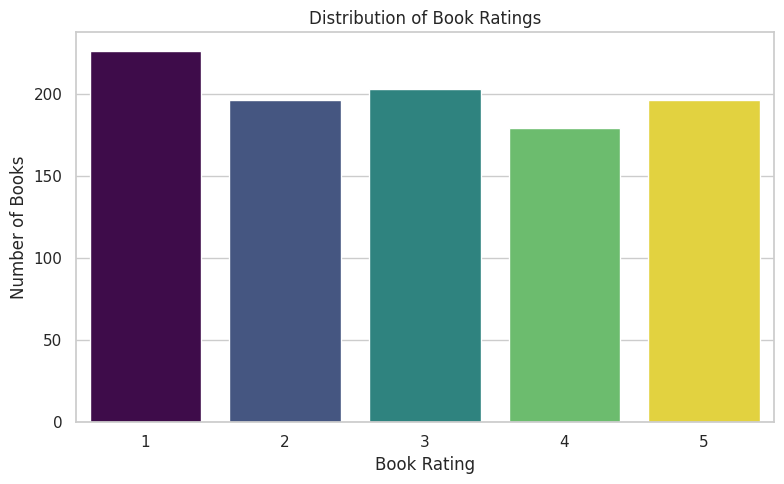

In [44]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="rating",
    hue="rating",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Book Prices Distribution

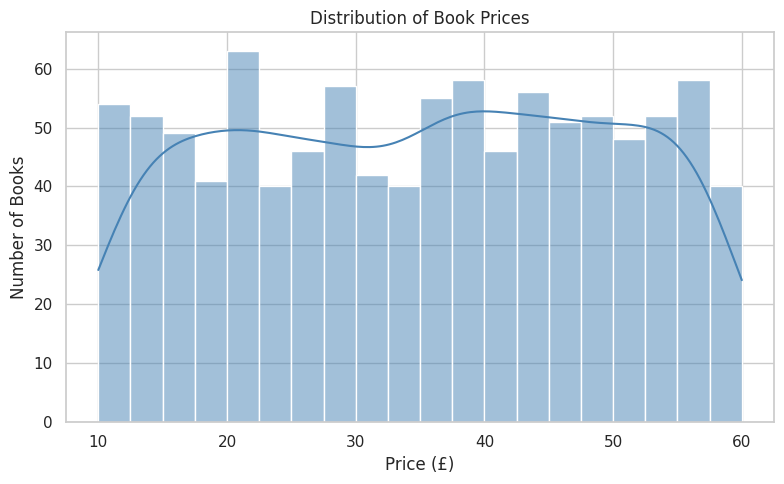

In [45]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="price",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Average Price

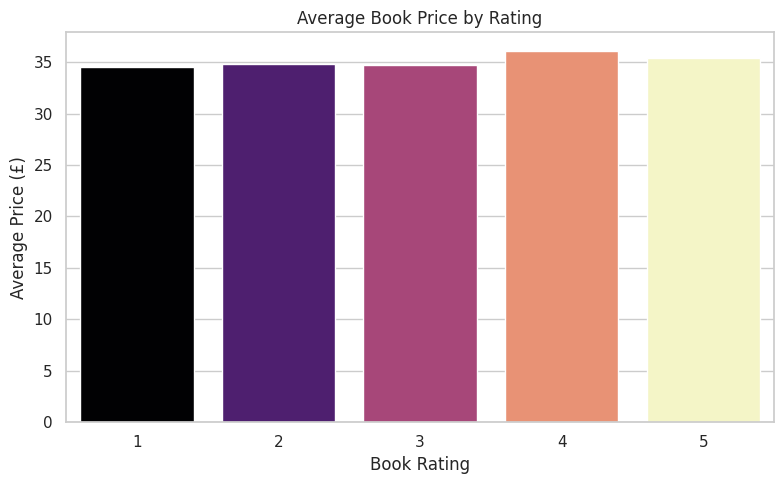

,rating,price
0,1,34.56
1,2,34.81
2,3,34.69
3,4,36.09
4,5,35.37


In [46]:
avg_price = (
    clean_df.groupby("rating")["price"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=avg_price,
    x="rating",
    y="price",
    hue="rating",
    palette="magma",
    legend=False
)

plt.title("Average Book Price by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()

display(avg_price.round(2))

# EDA Basic Statistics

In [47]:
print("Total books:", len(clean_df))
print("Average price:", round(clean_df["price"].mean(), 2))
print("Median price:", round(clean_df["price"].median(), 2))
print("Average rating:", round(clean_df["rating"].mean(), 2))

print("\nBooks by category:")
display(clean_df["category"].value_counts().head(10))

print("\nAvailability:")
display(clean_df["availability"].value_counts())

Total books: 1000
Average price: 35.07
Median price: 35.98
Average rating: 2.92

Books by category:


,count
category,
Default,152
Nonfiction,110
Sequential Art,75
Add a comment,67
Fiction,65
Young Adult,54
Fantasy,48
Romance,35
Mystery,32



Availability:


,count
availability,
In stock,1000


# Sentiment Analysis using TextBlob

In [48]:
# Missing descriptions empty text = replace
clean_df["description"] = clean_df["description"].fillna("")

# Description sentiment polarity
clean_df["sentiment_polarity"] = clean_df["description"].apply(
    lambda text: TextBlob(str(text)).sentiment.polarity
)

# Polarity basis sentiment label
def classify_sentiment(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

clean_df["sentiment"] = clean_df["sentiment_polarity"].apply(
    classify_sentiment
)

display(
    clean_df[
        ["title", "rating", "sentiment_polarity", "sentiment"]
    ].head(10)
)

,title,rating,sentiment_polarity,sentiment
0,A Light in the Attic,3,0.258352,Positive
1,Tipping the Velvet,1,0.124838,Positive
2,Soumission,1,0.000000,Neutral
3,Sharp Objects,4,-0.022523,Negative
4,Sapiens: A Brief History of Humankind,5,0.001667,Positive
5,The Requiem Red,1,0.029848,Positive
6,The Dirty Little Secrets of Getting Your Dream...,4,0.038088,Positive
7,The Coming Woman: A Novel Based on the Life of...,3,0.253470,Positive
8,The Boys in the Boat: Nine Americans and Their...,4,0.108681,Positive
9,The Black Maria,1,0.180726,Positive


# Sentiment Distribution

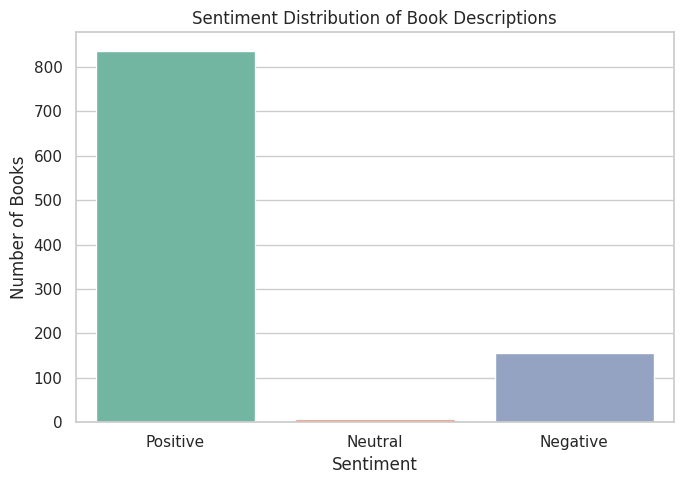

sentiment
Positive    836
Negative    157
Neutral       7
Name: count, dtype: int64


In [49]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=clean_df,
    x="sentiment",
    hue="sentiment",
    order=["Positive", "Neutral", "Negative"],
    palette="Set2",
    legend=False
)

plt.title("Sentiment Distribution of Book Descriptions")
plt.xlabel("Sentiment")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

print(clean_df["sentiment"].value_counts())

# Rating and Sentiment Correlation

In [50]:
correlation = clean_df[
    ["rating", "sentiment_polarity"]
].corr()

display(correlation)

print(
    "Rating aur sentiment polarity ka correlation:",
    round(correlation.loc["rating", "sentiment_polarity"], 3)
)

,rating,sentiment_polarity
rating,1.000000,0.066643
sentiment_polarity,0.066643,1.000000


Rating aur sentiment polarity ka correlation: 0.067


# Book Rating vs Sentiment

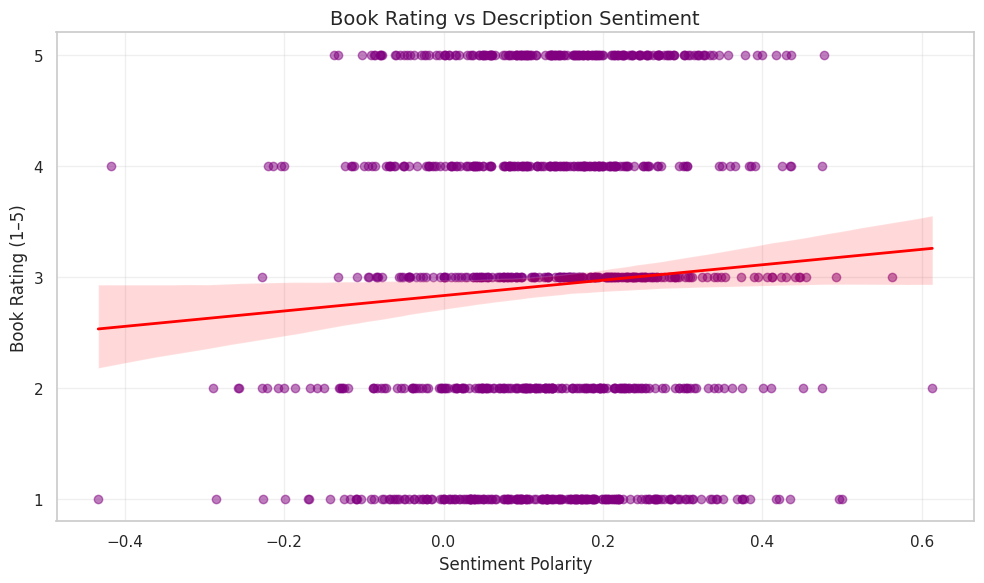

In [51]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=clean_df,
    x="sentiment_polarity",
    y="rating",
    scatter_kws={"alpha": 0.5, "color": "purple"},
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Book Rating vs Description Sentiment", fontsize=14)
plt.xlabel("Sentiment Polarity", fontsize=12)
plt.ylabel("Book Rating (1–5)", fontsize=12)

plt.yticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save Cleaned Dataset

In [52]:
os.makedirs("data/processed", exist_ok=True)

clean_df.to_csv(
    "data/processed/books_sentiment_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Final dataset saved successfully!")
print("Total records:", len(clean_df))
print("Total columns:", len(clean_df.columns))

Final dataset saved successfully!
Total records: 1000
Total columns: 11


In [53]:
# Final dataset CSV
clean_df.to_csv(
    "books_sentiment_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

# CSV download
files.download("books_sentiment_analysis.csv")
print(clean_df.columns.tolist())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['title', 'price', 'rating', 'category', 'stock', 'description', 'book_url', 'stock_quantity', 'availability', 'sentiment_polarity', 'sentiment']
